# PIB per cápita: evolución y comparación

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Carga, metadatos y calidad
[Indicador original](https://ourworldindata.org/grapher/gdp-per-capita-worldbank). Se utiliza la copia local
registrada con huella SHA-256. Los códigos de tres letras delimitan las entidades comparadas;
se excluyen agregados y faltantes del indicador. El metadato determina la unidad.

In [2]:
bruto = leer_owid("gdp-per-capita-worldbank")
display(bruto.head())
print("Dimensiones:", bruto.shape)
display(bruto.isna().sum().to_frame("faltantes"))
meta = metadatos("gdp-per-capita-worldbank")["columns"]["ny_gdp_pcap_pp_kd"]
print("Unidad:", meta.get("unit"), "Fuente:", meta.get("citationShort"))
datos = solo_paises(indicador("gdp-per-capita-worldbank", "ny_gdp_pcap_pp_kd", "gdp"))
datos = datos.dropna(subset=["gdp"]).sort_values(["entity", "year"])
assert not datos.duplicated(["entity", "year"]).any()

,entity,code,year,ny_gdp_pcap_pp_kd,owid_region
0,Afghanistan,AFG,2000,1617.8264,Asia
1,Afghanistan,AFG,2001,1454.1108,Asia
2,Afghanistan,AFG,2002,1774.3087,Asia
3,Afghanistan,AFG,2003,1815.9282,Asia
4,Afghanistan,AFG,2004,1776.9182,Asia


Dimensiones: (7445, 5)


,faltantes
entity,0
code,0
year,0
ny_gdp_pcap_pp_kd,0
owid_region,468


Unidad: international-$ in 2021 prices Fuente: Eurostat, OECD, IMF, and World Bank (2026) – with minor processing by Our World in Data


## 2. Serie de México y comparación internacional
Se conserva un periodo común 2000-2023 y se comparan las mismas unidades.
El gasto como porcentaje del PIB mide una proporción, no dólares gastados por habitante;
el PIB por persona mide producción promedio, no el ingreso de cada hogar.

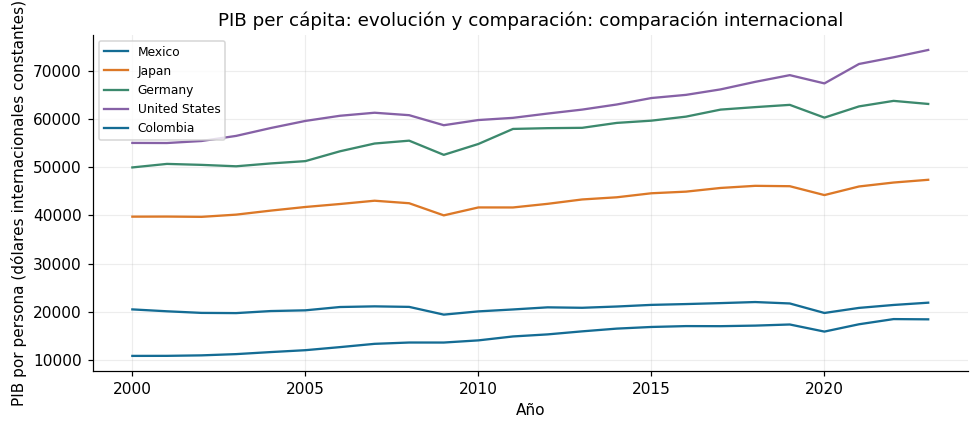

,year,gdp
4351,2018,21997.773
4352,2019,21704.186
4353,2020,19728.482
4354,2021,20782.588
4355,2022,21391.857
4356,2023,21864.924


In [3]:
paises = ["Mexico", "Japan", "Germany", "United States", "Colombia"]
recorte = datos.loc[datos.year.between(2000, 2023) & datos.entity.isin(paises)]
for pais in paises:
    serie = recorte.loc[recorte.entity.eq(pais)]
    plt.plot(serie.year, serie["gdp"], label=pais)
plt.xlabel("Año")
plt.ylabel("PIB por persona (dólares internacionales constantes)")
plt.title("PIB per cápita: evolución y comparación: comparación internacional")
plt.legend(fontsize=8)
guardar_figura("05_gdp_per_capita")
mx = recorte.loc[recorte.entity.eq("Mexico")]
display(mx[["year", "gdp"]].tail(6))

## 3. Ordenar un corte comparable (2023)
Se ordena un solo año y se muestran las diez entidades con valores más altos de las
disponibles. Este ranking no representa bienestar ni calidad sanitaria por sí mismo.

In [4]:
corte = datos.loc[datos.year.eq(2023)].copy()
top = corte.nlargest(10, "gdp")
display(top[["entity", "year", "gdp"]].round(2))
guardar_tabla(datos, "05_gdp_per_capita.csv")
ultimo = mx.iloc[-1]
primero = mx.iloc[0]
display(Markdown(f"México pasa de **{primero['gdp']:.2f}** en {int(primero.year)} "
                 f"a **{ultimo['gdp']:.2f}** en {int(ultimo.year)}. "
                 f"El corte de 2023 contiene **{len(corte)} entidades** con dato válido."))

,entity,year,gdp
6023,Singapore,2023,130296.84
3960,Luxembourg,2023,130048.92
3187,Ireland,2023,117659.73
5497,Qatar,2023,116159.14
3996,Macao,2023,104815.20
740,Bermuda,2023,102268.92
5033,Norway,2023,94364.96
6543,Switzerland,2023,85383.36
1227,Cayman Islands,2023,79580.89
955,Brunei,2023,76616.70


CSV guardado: U3_1_modelos_ml/data/processed/05_gdp_per_capita.csv (6,959 filas)


México pasa de **20470.49** en 2000 a **21864.92** en 2023. El corte de 2023 contiene **196 entidades** con dato válido.

## 4. Conclusión
La trayectoria muestra variaciones anuales que se perderían al comparar solo extremos.
Una variación de la proporción de gasto también puede reflejar cambios del denominador
(PIB), y no únicamente cambios de gasto. Las diferencias internacionales se describen;
atribuirlas a una política requiere indicadores adicionales y otro diseño de análisis.